# Hotel Bookings: Cancellation and Revenue Analysis

An end-to-end analysis of two Portuguese hotels (a **City Hotel** and a **Resort Hotel**): from raw, messy booking records to a data-backed recommendation for the hotel manager.

**Business question:** *Which bookings are most likely to be cancelled, how much revenue does that cost, and what should a manager do about it (for example, accept more bookings than rooms)?*

## Dataset

- **Where I found it:** the TidyTuesday project, week of 2020-02-11, "Hotel Bookings" (file `hotels.csv`):
  [github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-02-11](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-02-11)
- **Original data:** Antonio, N., de Almeida, A., & Nunes, L. (2019). *Hotel booking demand datasets.* Data in Brief, 22, 41-49. [doi:10.1016/j.dib.2018.11.126](https://doi.org/10.1016/j.dib.2018.11.126)
- **Prepared for TidyTuesday by:** Thomas Mock and Antoine Bichat.
- **Size:** 119,390 bookings, 32 columns, arrivals from July 2015 to August 2017.

## Questions answered

| # | Question |
|---|---|
| 1 | Cancellation rate by month and hotel |
| 2 | Cancellation rate by time between booking and arrival (lead time) |
| 3 | Cancellation rate by deposit type, and why it looks surprising |
| 4 | How to compare months fairly when the data covers them a different number of times |
| 5 | Revenue lost to cancellations |
| 6 | Top countries by number of bookings vs. by revenue |
| 7 | Room changes and their link to cancellations and special requests |
| 8 | Which bookings are riskiest, and how much overbooking is safe? |
| + | Hypothesis tests to check which differences are real and which could be chance |

## Notebook structure

0. Setup
1. Load and inspect the data
2. Data cleaning
3. Feature engineering
4. Outlier handling
5. Analysis (Questions 1 to 8)
6. Hypothesis testing

> **To run this notebook:** place `hotels.csv` in the same folder and run all cells from top to bottom.

## 0. Setup

All imports, constants and plotting helpers live here, so every chart in the notebook shares one consistent style.

In [2]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

pd.set_option("display.max_columns", None)

# ---------- constants ----------
DATA_PATH = "hotels.csv"
ALPHA = 0.05  # significance level used in every hypothesis test

MONTHS = ["January", "February", "March", "April", "May", "June",
          "July", "August", "September", "October", "November", "December"]
SUMMER_MONTHS = ["June", "July", "August"]
HOTELS = ["City Hotel", "Resort Hotel"]

# ---------- plot style ----------
HOTEL_COLORS = {"City Hotel": "#4682B4", "Resort Hotel": "#2E8B57"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})

SINGLE_FIGSIZE = (12, 6)      # one chart
WIDE_FIGSIZE = (16, 6)        # two charts side by side
GRID_FIGSIZE = (16, 11)       # 2 x 2 charts


# ---------- helpers ----------
def style_axis(ax, title, xlabel, ylabel, percent=False, rotate_x=0, legend_title=None,
               legend_outside=False):
    """Apply the same title, labels, grid and formatting to every chart."""
    ax.set_title(title, pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if percent:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=None))
    ax.tick_params(axis="x", rotation=rotate_x)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    if ax.get_legend() is not None and (legend_title is not None or legend_outside):
        if legend_outside:   # keep the legend off the bars
            ax.legend(title=legend_title, loc="upper left", bbox_to_anchor=(1.01, 1))
        else:
            ax.legend(title=legend_title)


def cancellation_rate_by(df, group_columns):
    """Cancellation rate (share of cancelled bookings) for every group."""
    return (
        df.groupby(group_columns, observed=True)["is_canceled"]
        .mean()
        .reset_index(name="cancellation_rate")
    )


def drop_rows(df, mask, reason):
    """Remove the rows where `mask` is True and report how many were removed."""
    print(f"{int(mask.sum()):>7,} rows removed: {reason}")
    return df[~mask]


def report_test(p_value, alpha=ALPHA):
    """Print the p-value and the decision of a hypothesis test."""
    decision = ("reject H0 (the difference is statistically significant)"
                if p_value < alpha
                else "fail to reject H0 (not enough evidence of a difference)")
    p_text = "< 1e-300" if p_value < 1e-300 else f"= {p_value:.3g}"
    print(f"p-value {p_text}  ->  {decision} at alpha = {alpha}")

## 1. Load and inspect the data

The raw file is read once into `hotels_raw` and is never modified. Every cleaning step works on a copy.

In [3]:
hotels_raw = pd.read_csv(DATA_PATH)
print(f"{hotels_raw.shape[0]:,} rows x {hotels_raw.shape[1]} columns")
hotels_raw.head()

119,390 rows x 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
hotels_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
hotels_raw.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


Text columns: the most frequent values of each (top 10), to spot placeholders such as `Undefined`.

In [6]:
for column in hotels_raw.select_dtypes(include=["object", "string"]).columns:
    print(f"------ {column} ------")
    print(hotels_raw[column].value_counts().head(10))
    print()

------ hotel ------
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

------ arrival_date_month ------
arrival_date_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794
Name: count, dtype: int64

------ meal ------
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

------ country ------
country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64

------ market_segment ------
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

------ distribution_channel ------
distributio

## 2. Data cleaning

Each rule below removes records that contradict themselves or cannot be real bookings. The reason for every rule is written next to it.

| Rule | Why |
|---|---|
| Zero nights but status `Check-Out` | A guest cannot check out without staying |
| `Undefined` market segment or distribution channel | Unknown booking source, only a handful of rows |
| Complementary segment with a price above zero | Complementary stays are free by definition |
| Price of zero, `Check-Out`, not complementary | A completed paid stay with no price recorded |
| Negative price | Impossible value |
| No guests at all (adults + children + babies = 0) | A booking needs at least one guest |
| Meal `Undefined` becomes `SC` | Both mean "no meal package", so the label is standardised |

**Duplicates:** rows identical in every column are removed. There is no booking ID, so some "duplicates" could be real group bookings. This decision affects the cancellation rates (see the limitations in Question 8).

In [7]:
hotels = hotels_raw.copy()

hotels = drop_rows(
    hotels,
    (hotels["stays_in_week_nights"] + hotels["stays_in_weekend_nights"] == 0)
    & (hotels["reservation_status"] == "Check-Out"),
    "zero nights but status Check-Out",
)
hotels = drop_rows(
    hotels,
    (hotels["market_segment"] == "Undefined") | (hotels["distribution_channel"] == "Undefined"),
    "undefined market segment or distribution channel",
)
hotels = drop_rows(
    hotels,
    (hotels["adr"] > 0) & (hotels["market_segment"] == "Complementary"),
    "complementary stay with a price above zero",
)
hotels = drop_rows(
    hotels,
    (hotels["adr"] == 0)
    & (hotels["reservation_status"] == "Check-Out")
    & (hotels["market_segment"] != "Complementary"),
    "paid stay (Check-Out) with price of zero",
)
hotels = drop_rows(hotels, hotels["adr"] < 0, "negative price")
hotels = drop_rows(
    hotels,
    hotels[["adults", "children", "babies"]].sum(axis=1) == 0,
    "booking with no guests",
)

# "Undefined" and "SC" both mean "no meal package"
hotels["meal"] = hotels["meal"].replace("Undefined", "SC")

# correct data types
hotels = hotels.astype({"is_repeated_guest": "bool", "children": "int64"})
hotels["reservation_status_date"] = pd.to_datetime(hotels["reservation_status_date"])

    680 rows removed: zero nights but status Check-Out
      5 rows removed: undefined market segment or distribution channel
     63 rows removed: complementary stay with a price above zero
    492 rows removed: paid stay (Check-Out) with price of zero
      1 rows removed: negative price
     60 rows removed: booking with no guests


### Missing values and duplicates

In [8]:
missing = hotels.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0])
print()
print("`agent` and `company` are ID codes, and a missing value means 'no agent / no company'.")
print("They are not used in the analysis, so they are left as they are.")

Columns with missing values:
country       469
agent       15931
company    111428
dtype: int64

`agent` and `company` are ID codes, and a missing value means 'no agent / no company'.
They are not used in the analysis, so they are left as they are.


In [9]:
hotels = drop_rows(hotels, hotels.duplicated(keep="first"), "duplicated rows")

 31,859 rows removed: duplicated rows


## 3. Feature engineering

New columns that the analysis needs:

| Column | Meaning |
|---|---|
| `arrival_date` | Real date built from year, month and day |
| `arrival_date_month` | Same month, but as an ordered category (January to December) so charts sort correctly |
| `total_nights` | Weekend nights + week nights |
| `lead_time_category` | Lead time grouped into readable ranges |
| `room_changed` | `True` when the assigned room differs from the reserved room |
| `adr_per_person` | Price per night divided by the number of guests |
| `total_revenue` | `adr` x `total_nights`: approximate revenue of the booking |

`adr` is the Average Daily Rate, i.e. the price per night.

In [10]:
LEAD_TIME_BINS = [0, 7, 14, 31, 62, 93, 155, 217, 279, 365, float("inf")]
LEAD_TIME_LABELS = ["0–1 Week", "1–2 Weeks", "2 Weeks–1 Month", "1–2 Months", "2–3 Months",
                    "3–5 Months", "5–7 Months", "7–9 Months", "9 Months–1 Year", "1 Year+"]

total_nights = hotels["stays_in_weekend_nights"] + hotels["stays_in_week_nights"]
total_guests = hotels[["adults", "children", "babies"]].sum(axis=1)

arrival_date = pd.to_datetime(
    hotels["arrival_date_year"].astype(str)
    + "-" + hotels["arrival_date_month"]
    + "-" + hotels["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
)

hotels = hotels.assign(
    arrival_date=arrival_date,
    arrival_date_month=pd.Categorical(hotels["arrival_date_month"], categories=MONTHS, ordered=True),
    total_nights=total_nights,
    lead_time_category=pd.cut(hotels["lead_time"], bins=LEAD_TIME_BINS,
                              labels=LEAD_TIME_LABELS, include_lowest=True),
    room_changed=hotels["reserved_room_type"] != hotels["assigned_room_type"],
    adr_per_person=(hotels["adr"] / total_guests).round(2),
    total_revenue=(hotels["adr"] * total_nights).round(2),
)

# columns that are no longer needed
hotels = hotels.drop(columns=["arrival_date_week_number", "arrival_date_day_of_month"])

## 4. Outlier handling

**Detection:** box plots of the numeric columns.

**Decision rule:** an outlier is only removed when it is *impossible*, not when it is merely extreme.
Extreme but real values (long stays, very long lead times for group bookings, luxury prices) are kept.

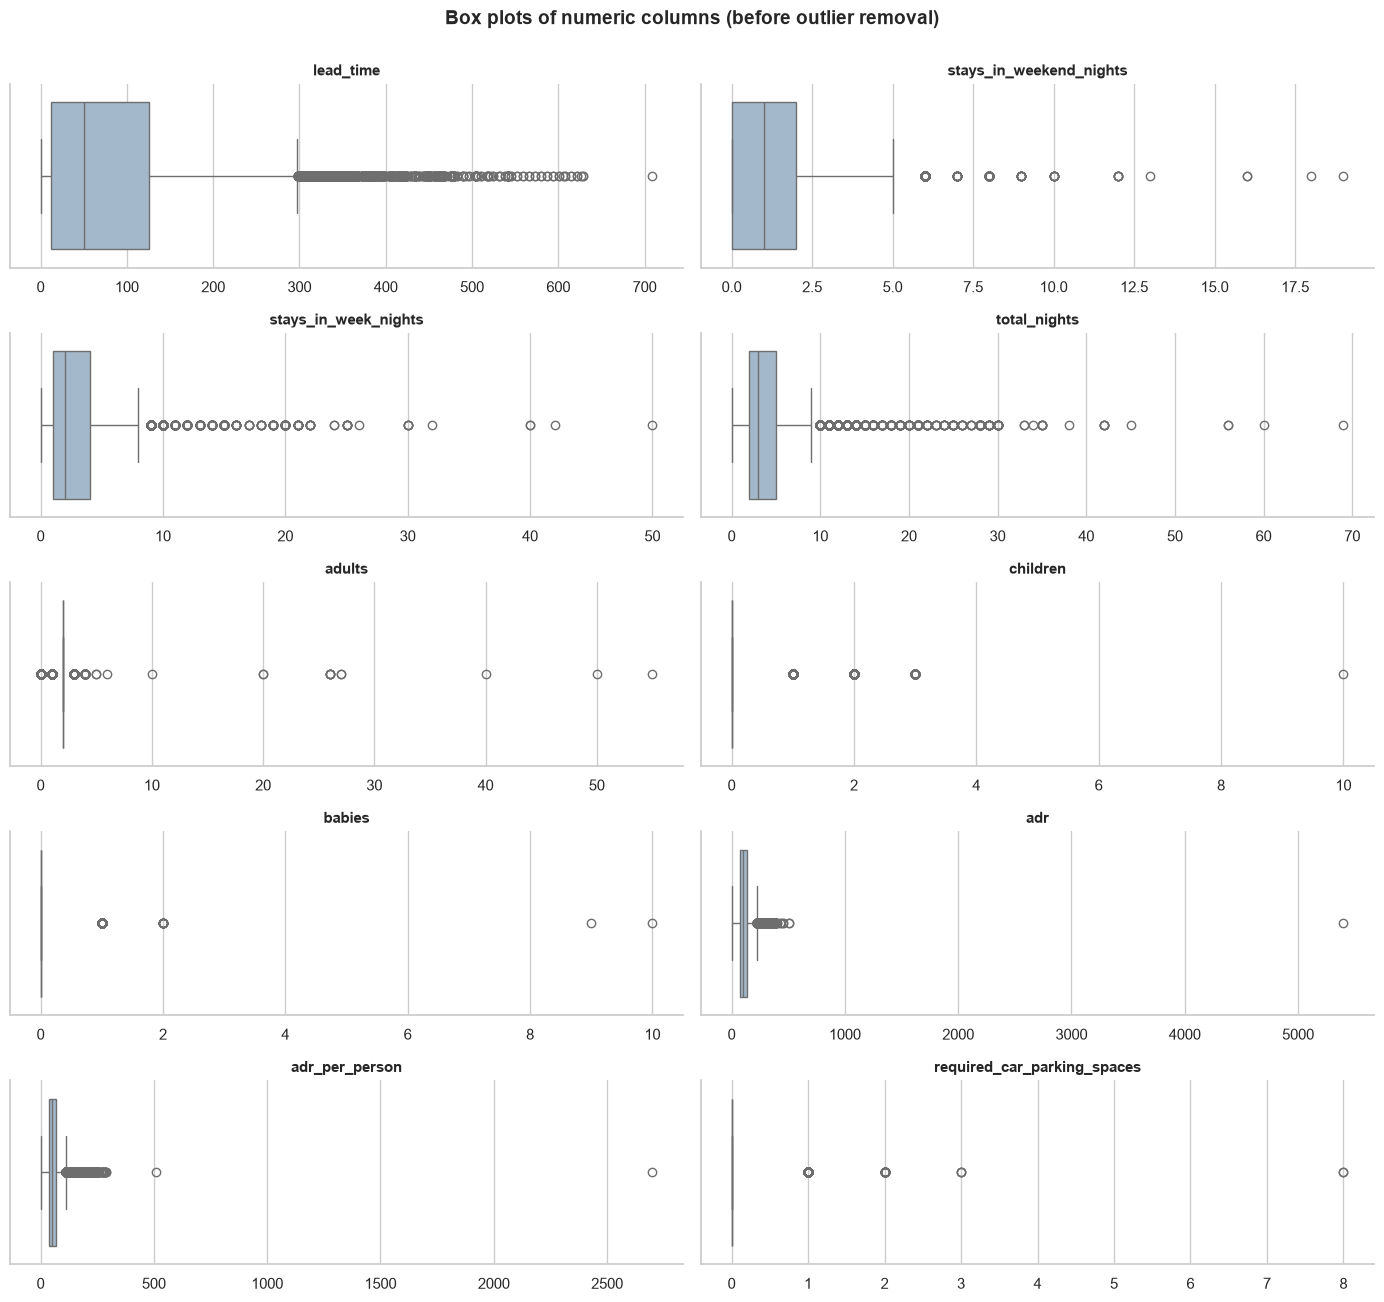

In [11]:
OUTLIER_COLUMNS = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
                   "total_nights", "adults", "children", "babies",
                   "adr", "adr_per_person", "required_car_parking_spaces"]
N_COLUMNS = 2
n_rows = math.ceil(len(OUTLIER_COLUMNS) / N_COLUMNS)

fig, axes = plt.subplots(n_rows, N_COLUMNS, figsize=(14, 2.6 * n_rows))
axes = axes.flatten()

for ax, column in zip(axes, OUTLIER_COLUMNS):
    sns.boxplot(data=hotels, x=column, color="#9DB8D2", ax=ax)
    ax.set_title(column, fontsize=11)
    ax.set_xlabel("")

for ax in axes[len(OUTLIER_COLUMNS):]:
    ax.axis("off")

fig.suptitle("Box plots of numeric columns (before outlier removal)", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Removed (clear data errors):**

| Rule | Reason |
|---|---|
| `adr` above 1000 | One booking at 5400 per night, ten times the next highest value |
| `babies` of 9 or more, `children` of 10 or more | Not plausible for a hotel room |
| `adr_per_person` above 500 | Removes the 5400 booking again (2700 per person) and **one more booking**: 510 per night for a single guest. *Judgment call:* a very high but possible price. |
| `lead_time` above 700 days | One direct booking with a lead time of 709 days, while the next highest value is 629. *Judgment call:* treated as a likely recording error. |

Both judgment calls remove one booking each, so they have almost no effect on the results. They could also be kept.

**Kept on purpose:** long stays (up to 69 nights, real long-term guests), large group bookings (many adults, all of type `Group`), and other high prices (up to about 508 per night, plausible luxury rooms).

In [12]:
ADR_MAX = 1000
BABIES_MAX = 9
CHILDREN_MAX = 10
ADR_PER_PERSON_MAX = 500
LEAD_TIME_MAX = 700

outlier_mask = (
    (hotels["adr"] > ADR_MAX)
    | (hotels["babies"] >= BABIES_MAX)
    | (hotels["children"] >= CHILDREN_MAX)
    | (hotels["adr_per_person"] > ADR_PER_PERSON_MAX)
    | (hotels["lead_time"] > LEAD_TIME_MAX)
)
hotels = drop_rows(hotels, outlier_mask, "clear data errors (see table above)")

print(f"\nFinal dataset: {hotels.shape[0]:,} rows x {hotels.shape[1]} columns")
# hotels.to_csv("hotels_clean.csv", index=False)   # uncomment to save the cleaned data

      6 rows removed: clear data errors (see table above)

Final dataset: 86,224 rows x 36 columns


## 5. Analysis

Every question follows the same pattern: a short explanation of the method, the code, and a chart.
Cancellation rates are always the **mean of `is_canceled`** (0 = kept, 1 = cancelled), i.e. the share of bookings that were cancelled. A rate is used instead of a count because groups have different sizes.

### Question 1: Cancellation rate by month and hotel

*Calculate the cancellation rate for each month of the year and for each hotel. Which months have the highest rate, and do the two hotels follow a similar pattern?*

**Method:** group by hotel and arrival month, take the mean of `is_canceled`, and draw both hotels on one line chart so they can be compared directly.

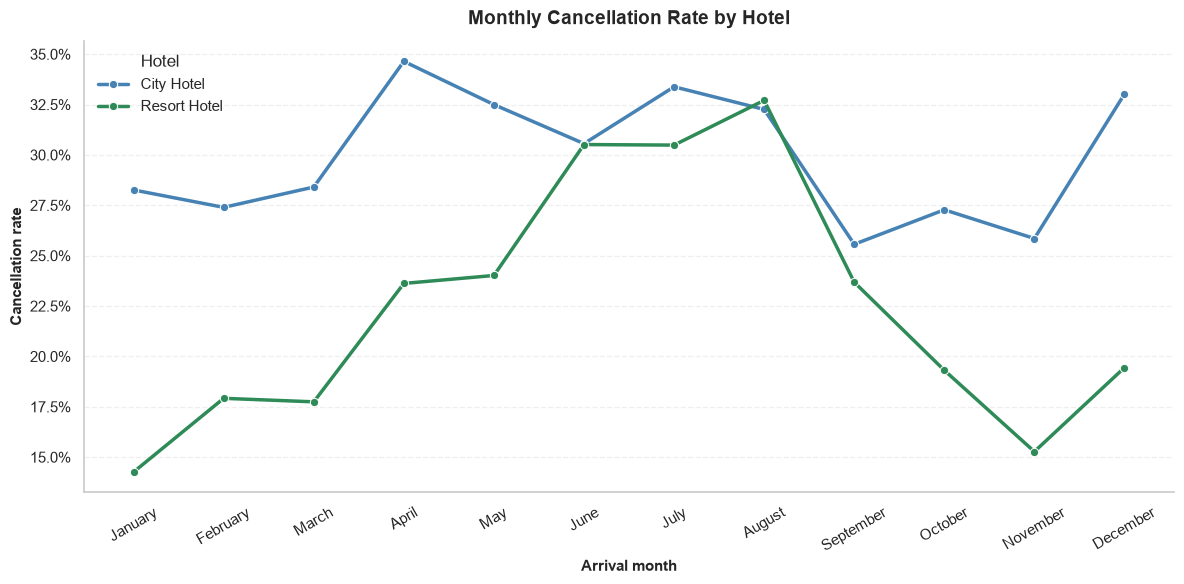

In [13]:
monthly_cancellation = cancellation_rate_by(hotels, ["hotel", "arrival_date_month"])

fig, ax = plt.subplots(figsize=SINGLE_FIGSIZE)
sns.lineplot(
    data=monthly_cancellation,
    x="arrival_date_month", y="cancellation_rate",
    hue="hotel", palette=HOTEL_COLORS,
    marker="o", linewidth=2.5, sort=False, ax=ax,
)
style_axis(ax, "Monthly Cancellation Rate by Hotel", "Arrival month", "Cancellation rate",
           percent=True, rotate_x=30, legend_title="Hotel")
plt.tight_layout()
plt.show()

### Question 2: Cancellation rate by lead time

*Split the time between booking and arrival into ranges and calculate the cancellation rate of each range. How does the rate change as lead time grows, and is the relationship simple?*

**Method:** `lead_time_category` (created in the feature engineering step) groups lead time into ordered ranges.

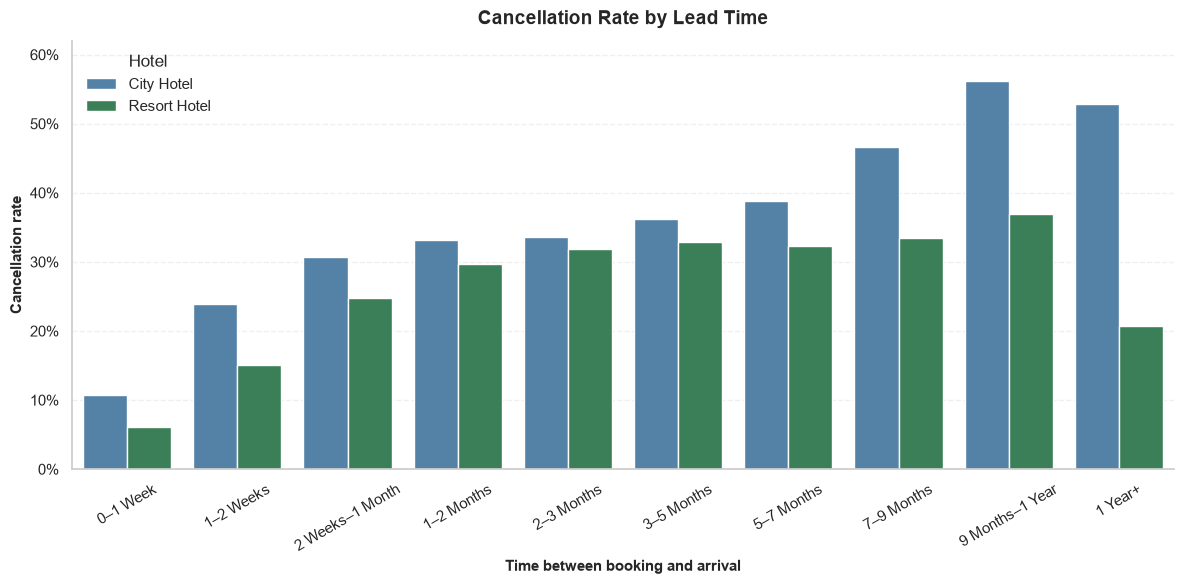

In [14]:
cancellation_by_lead_time = cancellation_rate_by(hotels, ["hotel", "lead_time_category"])

fig, ax = plt.subplots(figsize=SINGLE_FIGSIZE)
sns.barplot(
    data=cancellation_by_lead_time,
    x="lead_time_category", y="cancellation_rate",
    hue="hotel", palette=HOTEL_COLORS, ax=ax,
)
ax.set_ylim(0, 0.62)
style_axis(ax, "Cancellation Rate by Lead Time", "Time between booking and arrival",
           "Cancellation rate", percent=True, rotate_x=30, legend_title="Hotel")
plt.tight_layout()
plt.show()

### Question 3: Cancellation rate by deposit type

*Calculate the cancellation rate for each deposit type and compare it with what you expected. If the result is surprising, look at other columns to find a reason.*

**Method:** first the cancellation rate per deposit type, then (because one result looks surprising) a look at *who* is inside each deposit type: the mix of market segments and customer types.

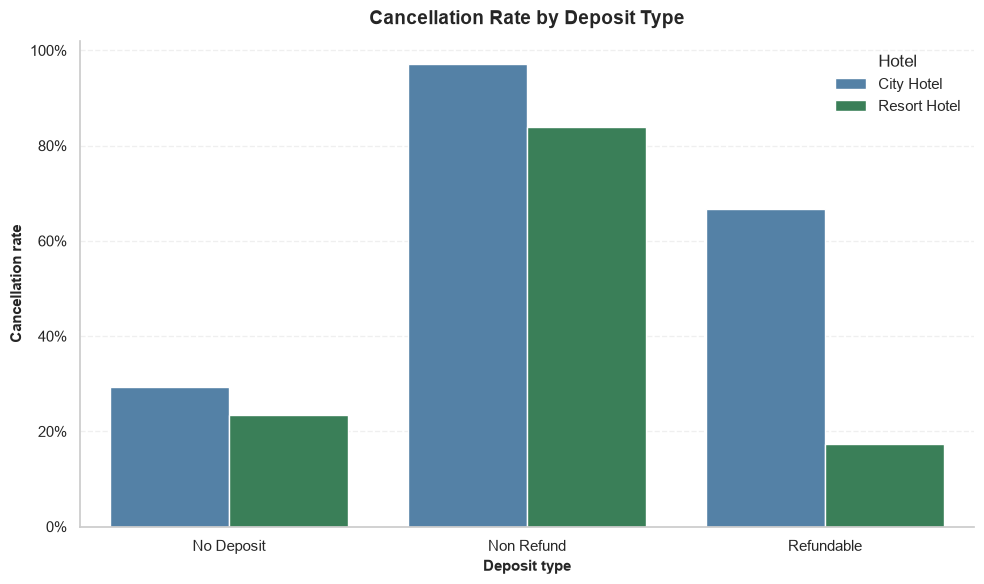

In [15]:
cancellation_by_deposit = cancellation_rate_by(hotels, ["hotel", "deposit_type"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=cancellation_by_deposit,
    x="deposit_type", y="cancellation_rate",
    hue="hotel", palette=HOTEL_COLORS, ax=ax,
)
ax.set_ylim(0, 1.02)
style_axis(ax, "Cancellation Rate by Deposit Type", "Deposit type", "Cancellation rate",
           percent=True, legend_title="Hotel")
plt.tight_layout()
plt.show()

Group sizes matter when comparing rates: a rate from a very small group is unreliable.

In [16]:
(hotels
 .groupby(["hotel", "deposit_type"], observed=True)
 .size()
 .rename("bookings")
 .reset_index())

,hotel,deposit_type,bookings
0,City Hotel,No Deposit,51926
1,City Hotel,Non Refund,844
2,City Hotel,Refundable,15
3,Resort Hotel,No Deposit,33154
4,Resort Hotel,Non Refund,193
5,Resort Hotel,Refundable,92


**Who is inside each deposit type?** For every deposit type, the share of bookings coming from each market segment and customer type (each bar group adds up to 100%).

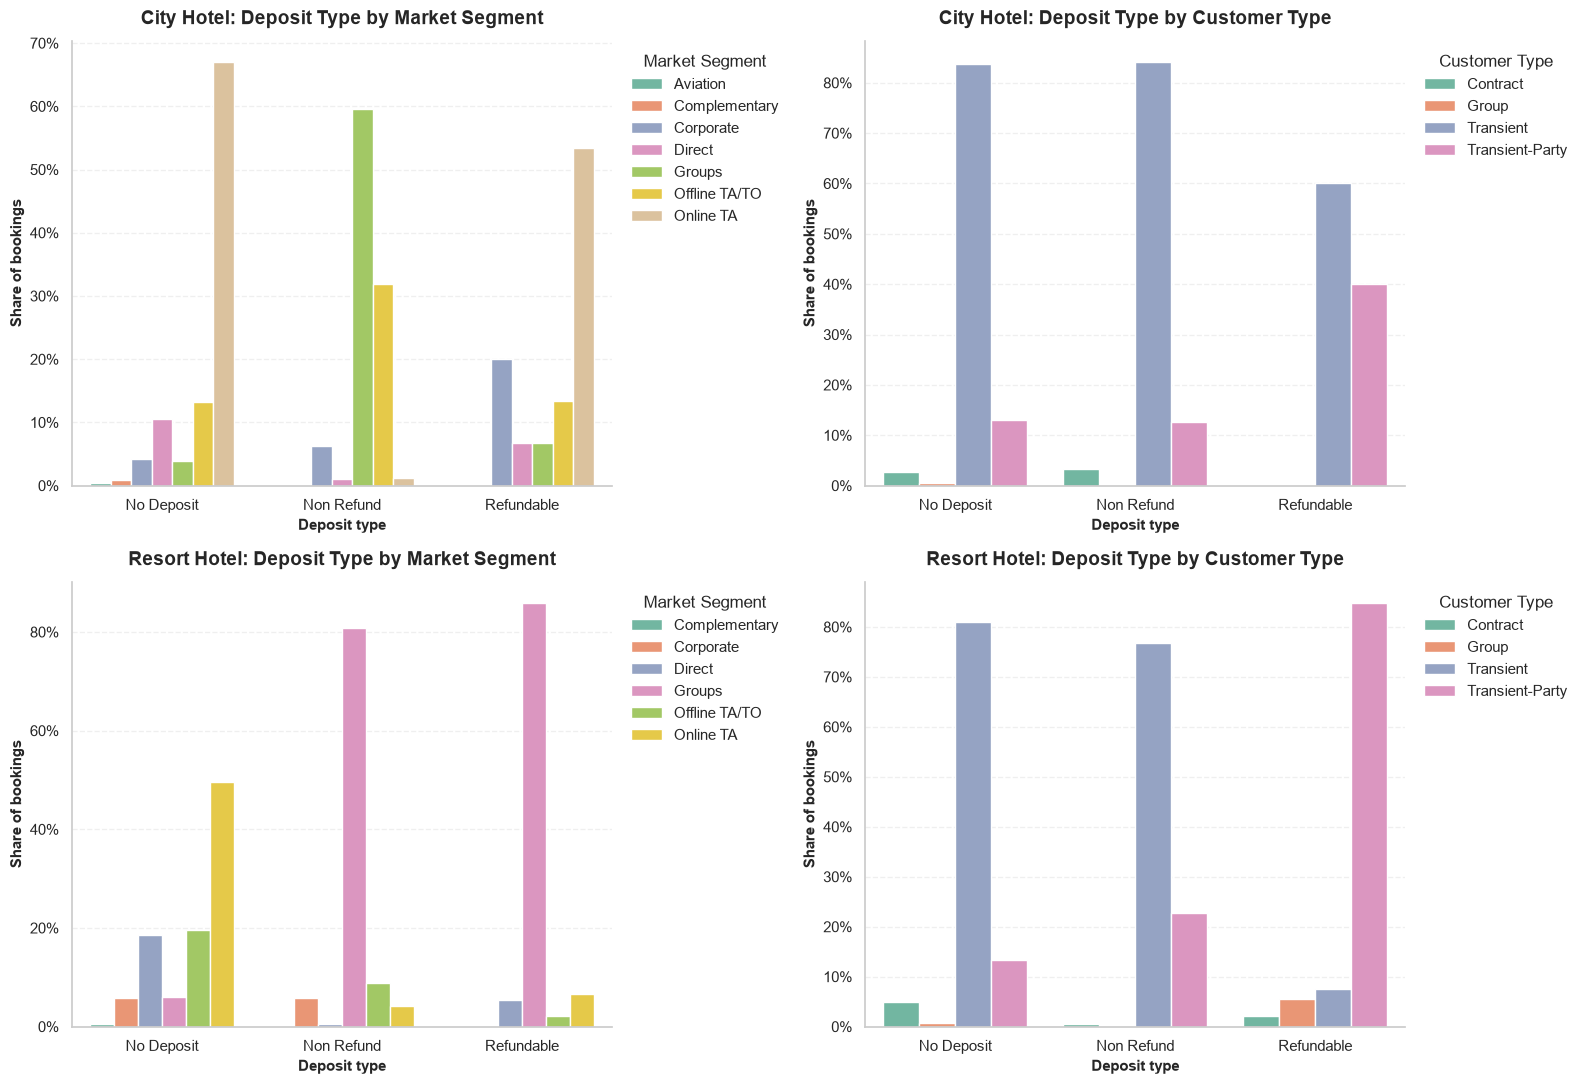

In [17]:
def composition_by(hotel, category_column):
    """Share of each category inside every deposit type of one hotel."""
    subset = hotels[hotels["hotel"] == hotel]
    shares = pd.crosstab(subset["deposit_type"], subset[category_column], normalize="index")
    return shares.reset_index().melt(id_vars="deposit_type", var_name=category_column,
                                     value_name="share")


fig, axes = plt.subplots(2, 2, figsize=GRID_FIGSIZE)

for row, hotel in enumerate(HOTELS):
    for col, category in enumerate(["market_segment", "customer_type"]):
        ax = axes[row, col]
        sns.barplot(data=composition_by(hotel, category), x="deposit_type", y="share",
                    hue=category, palette="Set2", ax=ax)
        style_axis(ax, f"{hotel}: Deposit Type by {category.replace('_', ' ').title()}",
                   "Deposit type", "Share of bookings", percent=True,
                   legend_title=category.replace("_", " ").title(), legend_outside=True)

plt.tight_layout()
plt.show()

### Question 4: Comparing months fairly

*The data runs from July 2015 to August 2017, so July and August appear three times and every other month twice. What goes wrong if we compare monthly booking counts directly, and how can seasonality be shown without that error?*

**The problem:** July and August have three years of data, the other months only two, so their raw totals are inflated by about 50%.

**The fix:** divide each month's bookings by the number of years in which that month appears, i.e. use the *average bookings per year*.

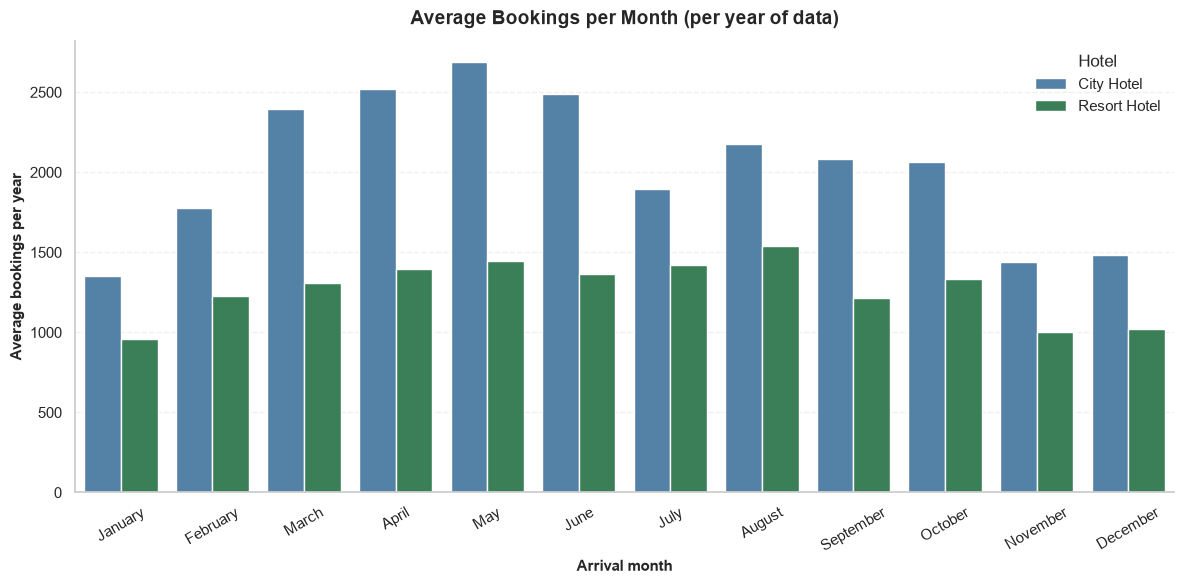

In [18]:
bookings_per_month = (
    hotels.groupby(["hotel", "arrival_date_month"], observed=True)
    .agg(bookings=("hotel", "size"), years=("arrival_date_year", "nunique"))
    .reset_index()
)
bookings_per_month["avg_bookings_per_year"] = bookings_per_month["bookings"] / bookings_per_month["years"]

fig, ax = plt.subplots(figsize=SINGLE_FIGSIZE)
sns.barplot(data=bookings_per_month, x="arrival_date_month", y="avg_bookings_per_year",
            hue="hotel", palette=HOTEL_COLORS, ax=ax)
style_axis(ax, "Average Bookings per Month (per year of data)", "Arrival month",
           "Average bookings per year", rotate_x=30, legend_title="Hotel")
plt.tight_layout()
plt.show()

### Question 5: Revenue lost to cancellations

*Estimate each booking's revenue as price per night x number of nights. For each month, how much revenue would the hotel have had if nothing had been cancelled, and what percentage was lost?*

**Method (first version):** for every month, the **average revenue per booking** of kept bookings (`Real`) and of cancelled bookings (`Lost`) are stacked. Using averages instead of totals avoids the July/August three-year inflation described in Question 4. The bottom row shows the same bars as shares of 100%.

> **Important:** the bottom row is the share of two *averages* (the mean kept booking vs. the mean cancelled booking). It ignores how many bookings are in each group, so it does **not** measure the share of total revenue that was lost. The totals-based version further below is the one that answers the question.

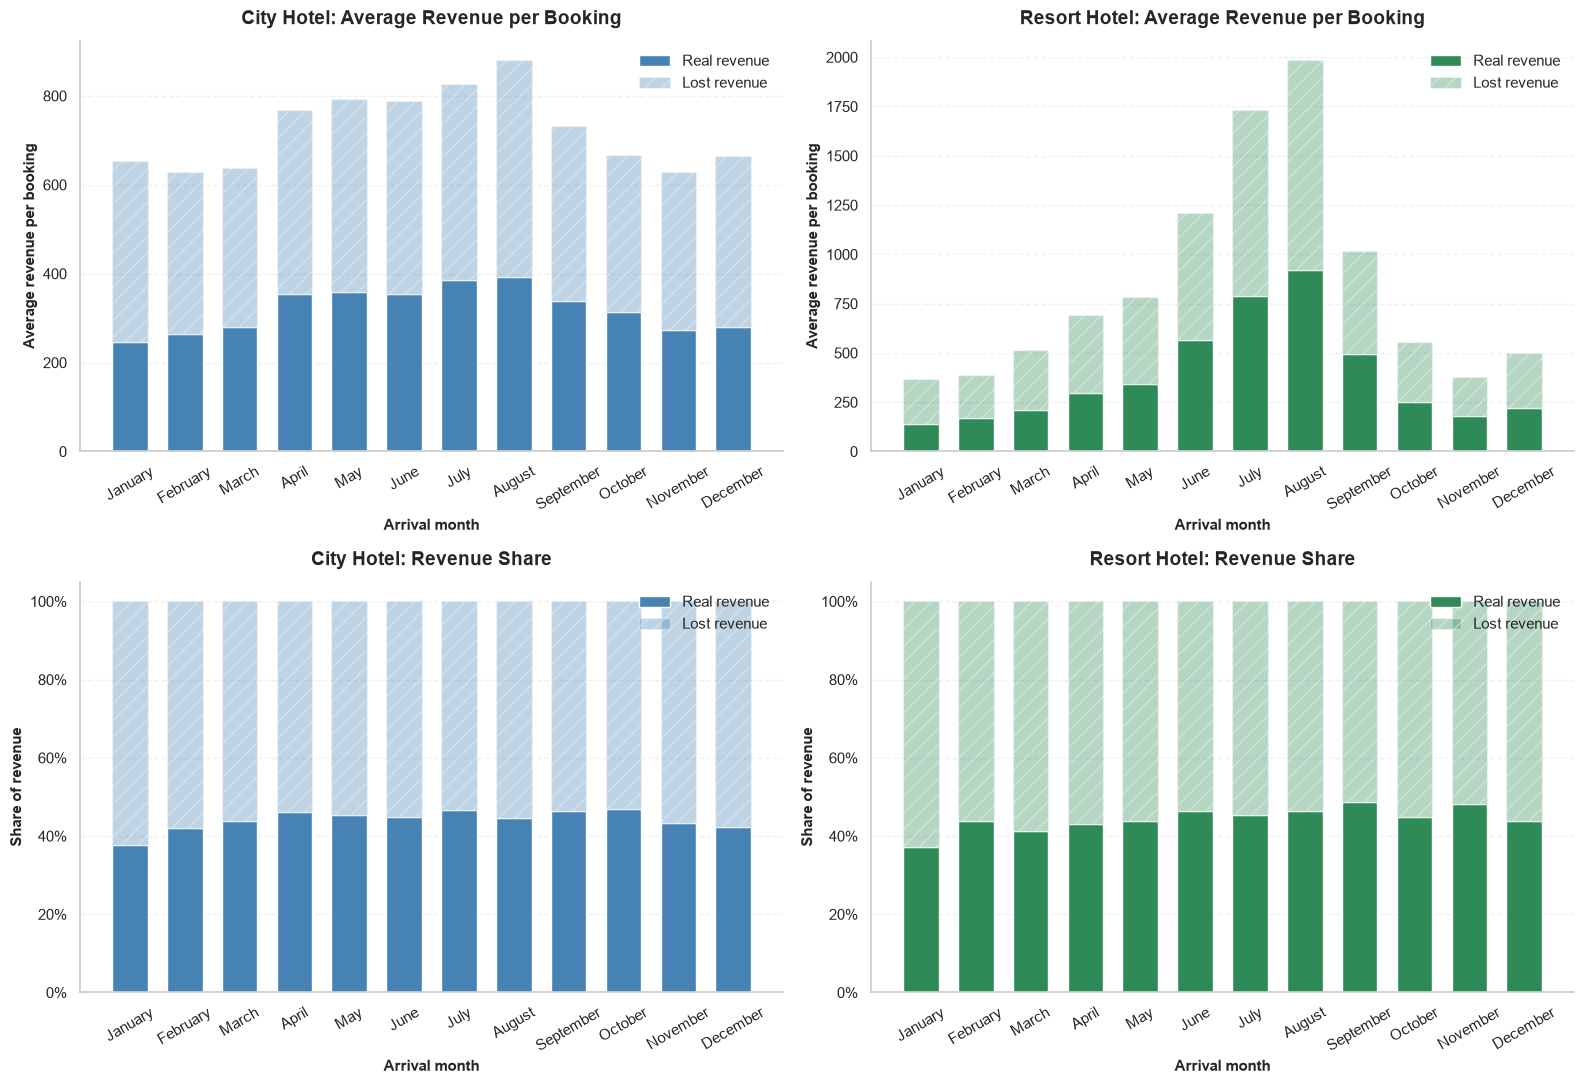

In [19]:
def average_revenue_by_month(hotel):
    """Average revenue per booking by month: columns 0 = kept, 1 = cancelled."""
    subset = hotels[hotels["hotel"] == hotel]
    return (subset.groupby(["arrival_date_month", "is_canceled"], observed=True)["total_revenue"]
            .mean().unstack("is_canceled"))


def plot_stacked_revenue(ax, hotel, as_share):
    revenue = average_revenue_by_month(hotel)
    kept, lost = revenue[0], revenue[1]
    if as_share:
        kept, lost = kept / (kept + lost), lost / (kept + lost)

    color = HOTEL_COLORS[hotel]
    positions = range(len(kept))
    ax.bar(positions, kept, width=0.65, color=color, label="Real revenue")
    ax.bar(positions, lost, width=0.65, bottom=kept, color=color, alpha=0.35,
           hatch="//", edgecolor="white", label="Lost revenue")
    ax.set_xticks(list(positions))
    ax.set_xticklabels(kept.index.astype(str))
    style_axis(ax, f"{hotel}: " + ("Revenue Share" if as_share else "Average Revenue per Booking"),
               "Arrival month", "Share of revenue" if as_share else "Average revenue per booking",
               percent=as_share, rotate_x=30)
    ax.legend()


fig, axes = plt.subplots(2, 2, figsize=GRID_FIGSIZE)
for col, hotel in enumerate(HOTELS):
    plot_stacked_revenue(axes[0, col], hotel, as_share=False)
    plot_stacked_revenue(axes[1, col], hotel, as_share=True)

plt.tight_layout()
plt.show()

**A more precise version (totals instead of averages).** The share of revenue lost is `cancelled revenue / (kept + cancelled revenue)`. When both parts are *totals within the same month*, the number of years cancels out, so no correction is needed.

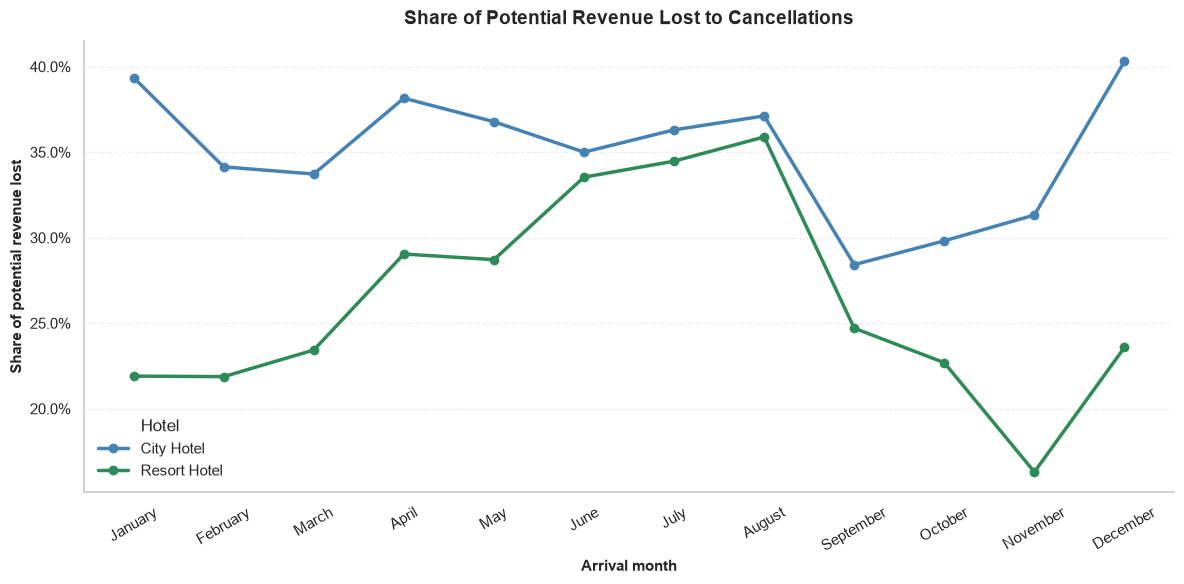

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,0.394,0.219
February,0.341,0.219
March,0.337,0.234
April,0.382,0.290
May,0.368,0.287
June,0.350,0.335
July,0.363,0.345
August,0.371,0.359
September,0.284,0.247


In [20]:
revenue_totals = (
    hotels.groupby(["hotel", "arrival_date_month", "is_canceled"], observed=True)["total_revenue"]
    .sum().unstack("is_canceled")
)
lost_revenue_share = (revenue_totals[1] / (revenue_totals[0] + revenue_totals[1])).unstack("hotel")

fig, ax = plt.subplots(figsize=SINGLE_FIGSIZE)
for hotel in HOTELS:
    ax.plot(lost_revenue_share.index.astype(str), lost_revenue_share[hotel], marker="o",
            linewidth=2.5, color=HOTEL_COLORS[hotel], label=hotel)
ax.legend()

style_axis(ax, "Share of Potential Revenue Lost to Cancellations", "Arrival month",
           "Share of potential revenue lost", percent=True, rotate_x=30, legend_title="Hotel")
plt.tight_layout()
plt.show()

lost_revenue_share.round(3)

#### Extra: why is the Resort Hotel's revenue higher in summer?

Revenue per booking = price per night x nights, so two things can drive it. Both are checked below for the Resort Hotel.

In [21]:
resort = hotels[hotels["hotel"] == "Resort Hotel"]
summer_mask = resort["arrival_date_month"].isin(SUMMER_MONTHS)

avg_nights_summer = resort[summer_mask].groupby("arrival_date_month", observed=True)["total_nights"].mean().mean()
avg_nights_other = resort[~summer_mask].groupby("arrival_date_month", observed=True)["total_nights"].mean().mean()

print(f"Average stay in Jun-Aug: {avg_nights_summer:.2f} nights")
print(f"Average stay in other months: {avg_nights_other:.2f} nights")
print(f"Summer stays are {(avg_nights_summer / avg_nights_other) - 1:.0%} longer")

Average stay in Jun-Aug: 5.39 nights
Average stay in other months: 3.89 nights
Summer stays are 39% longer


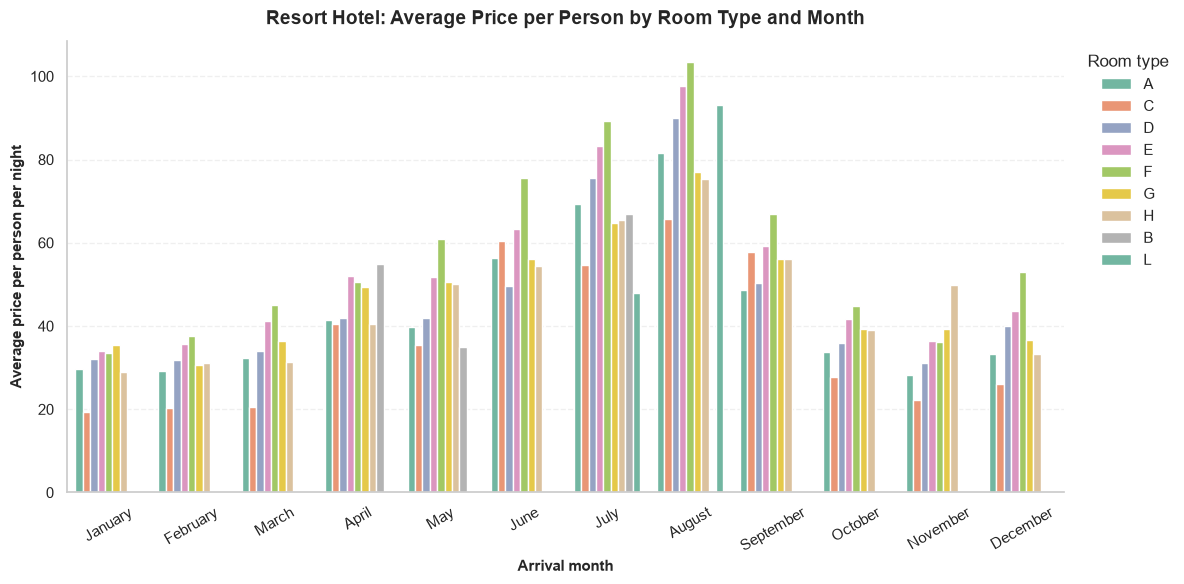

In [22]:
price_by_room_type = (
    resort.groupby(["arrival_date_month", "reserved_room_type"], observed=True)["adr_per_person"]
    .mean().reset_index(name="avg_price_per_person")
)

fig, ax = plt.subplots(figsize=SINGLE_FIGSIZE)
sns.barplot(data=price_by_room_type, x="arrival_date_month", y="avg_price_per_person",
            hue="reserved_room_type", palette="Set2", ax=ax)
style_axis(ax, "Resort Hotel: Average Price per Person by Room Type and Month",
           "Arrival month", "Average price per person per night", rotate_x=30,
           legend_title="Room type", legend_outside=True)
plt.tight_layout()
plt.show()

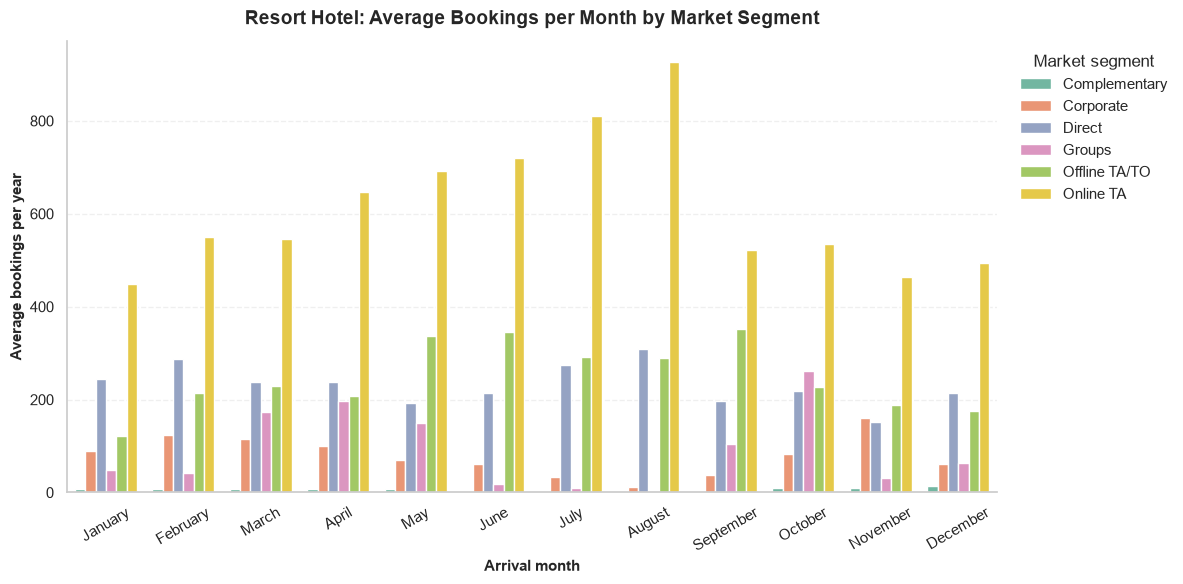

In [23]:
segment_by_month = (
    resort.groupby(["arrival_date_month", "market_segment"], observed=True)
    .agg(bookings=("hotel", "size"), years=("arrival_date_year", "nunique"))
    .reset_index()
)
segment_by_month["avg_bookings_per_year"] = segment_by_month["bookings"] / segment_by_month["years"]

fig, ax = plt.subplots(figsize=SINGLE_FIGSIZE)
sns.barplot(data=segment_by_month, x="arrival_date_month", y="avg_bookings_per_year",
            hue="market_segment", palette="Set2", ax=ax)
style_axis(ax, "Resort Hotel: Average Bookings per Month by Market Segment",
           "Arrival month", "Average bookings per year", rotate_x=30,
           legend_title="Market segment", legend_outside=True)
plt.tight_layout()
plt.show()

### Question 6: Top countries by bookings and by revenue

*Find the top 10 countries by number of bookings and by total revenue. Are the two lists the same, and what does the difference say about the guests of those countries?*

**Method:** only bookings that were **not cancelled** are used for both rankings, so "bookings" and "revenue" describe stays that really happened.

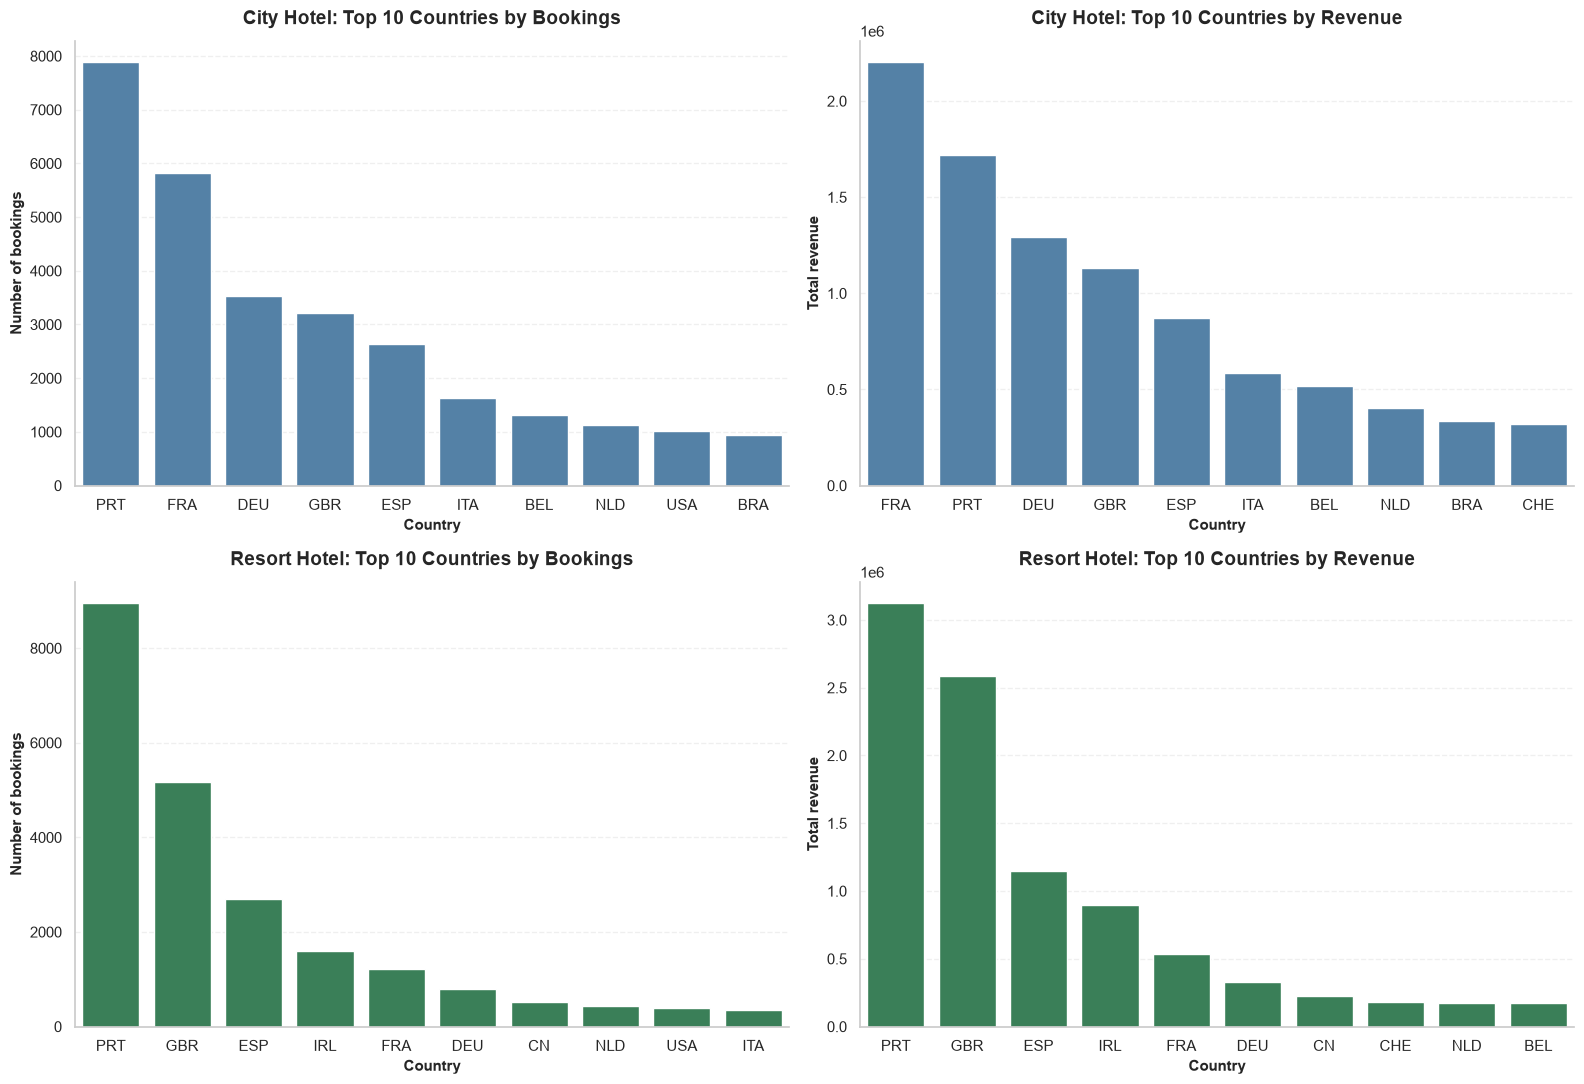

In [24]:
def top_countries(hotel, metric, n=10):
    """Top countries of one hotel, ranked by number of stays or by total revenue."""
    stays = hotels[(hotels["hotel"] == hotel) & (hotels["is_canceled"] == 0)]
    grouped = stays.groupby("country")
    if metric == "bookings":
        ranking = grouped.size().rename("value")
    else:
        ranking = grouped["total_revenue"].sum().rename("value")
    return ranking.sort_values(ascending=False).head(n).reset_index()


fig, axes = plt.subplots(2, 2, figsize=GRID_FIGSIZE)

for row, hotel in enumerate(HOTELS):
    for col, (metric, label) in enumerate([("bookings", "Number of bookings"),
                                           ("revenue", "Total revenue")]):
        ax = axes[row, col]
        sns.barplot(data=top_countries(hotel, metric), x="country", y="value",
                    color=HOTEL_COLORS[hotel], ax=ax)
        style_axis(ax, f"{hotel}: Top 10 Countries by {metric.title()}", "Country", label)

plt.tight_layout()
plt.show()

### Question 7: Room changes

*In what percentage of bookings is the assigned room type different from the reserved one? Is a room change related to cancellations or to the number of special requests?*

**Method:** `room_changed` is `True` when the reserved and assigned room types differ. The first chart gives the share of bookings with a room change; the next two compare the cancellation rate and the share of bookings with at least one special request between changed and unchanged bookings.

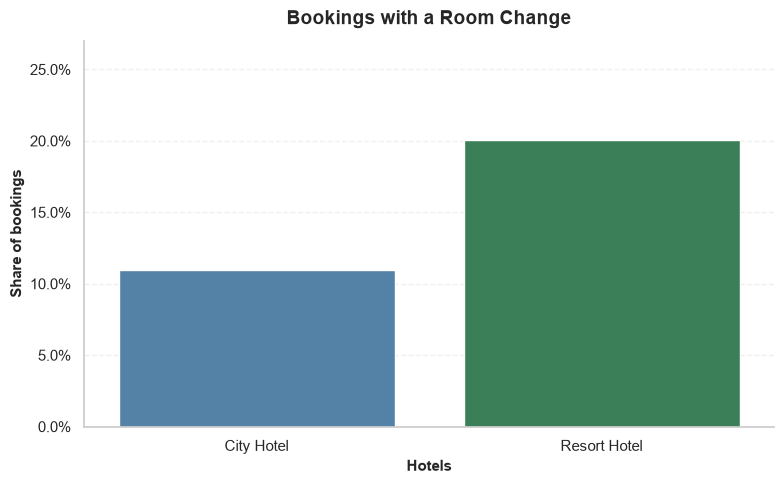

In [25]:
room_change_share = hotels.groupby("hotel")["room_changed"].mean().reset_index(name="share_room_changed")

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=room_change_share, x="hotel", y="share_room_changed",
            hue="hotel", palette=HOTEL_COLORS, legend=False, ax=ax)
ax.set_ylim(0, 0.27)
style_axis(ax, "Bookings with a Room Change", "Hotels", "Share of bookings", percent=True)
plt.tight_layout()
plt.show()

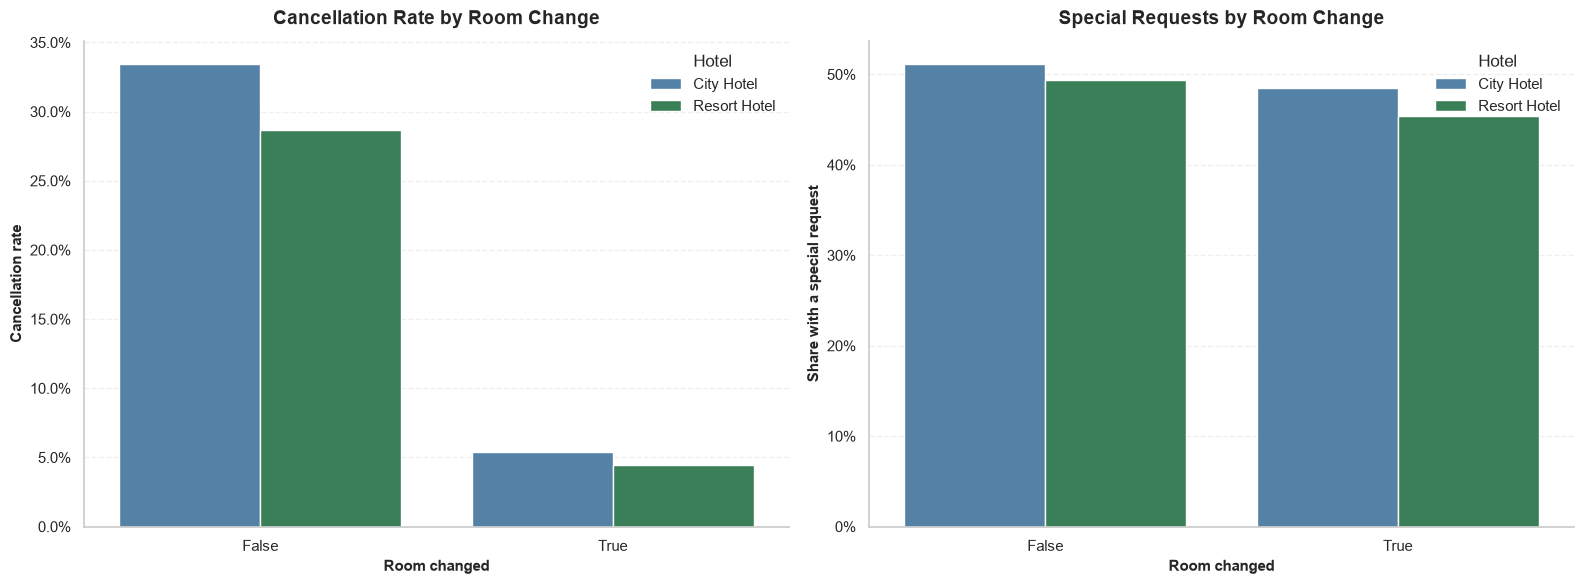

In [26]:
def share_by_room_change(column):
    """Share of bookings with a non-zero value in `column`, split by hotel and room change."""
    return (hotels.assign(flag=hotels[column] > 0)
            .groupby(["hotel", "room_changed"])["flag"].mean()
            .reset_index(name="share"))


fig, axes = plt.subplots(1, 2, figsize=WIDE_FIGSIZE)
panels = [
    ("is_canceled", "Cancellation Rate by Room Change", "Cancellation rate"),
    ("total_of_special_requests", "Special Requests by Room Change", "Share with a special request"),
]

for ax, (column, title, ylabel) in zip(axes, panels):
    sns.barplot(data=share_by_room_change(column), x="room_changed", y="share",
                hue="hotel", palette=HOTEL_COLORS, ax=ax)
    style_axis(ax, title, "Room changed", ylabel, percent=True, legend_title="Hotel")

plt.tight_layout()
plt.show()

### Question 8: Which bookings are riskiest, and how much overbooking is safe?

*Suppose the manager wants to accept more bookings than there are rooms (overbooking). Based on the data, which kinds of bookings are most likely to be cancelled? Finish with one specific recommendation backed by numbers and charts.*

**Approach**

1. **Explore:** cancellation rate by market segment, repeated-guest status and country.
2. **Turn findings into rules:** explicit, testable conditions per hotel, grouped into risk tiers.
3. **Check each tier:** size, cancellation rate with a confidence interval, and how many of all cancellations it captures.
4. **Check timing:** overbooking only works with *late* cancellations. A room that is cancelled months ahead can simply be sold again, so it does not need overbooking.
5. **Recommend:** how many extra rooms can be sold per night, using the historical number of late cancellations per day.

#### Step 1: Explore

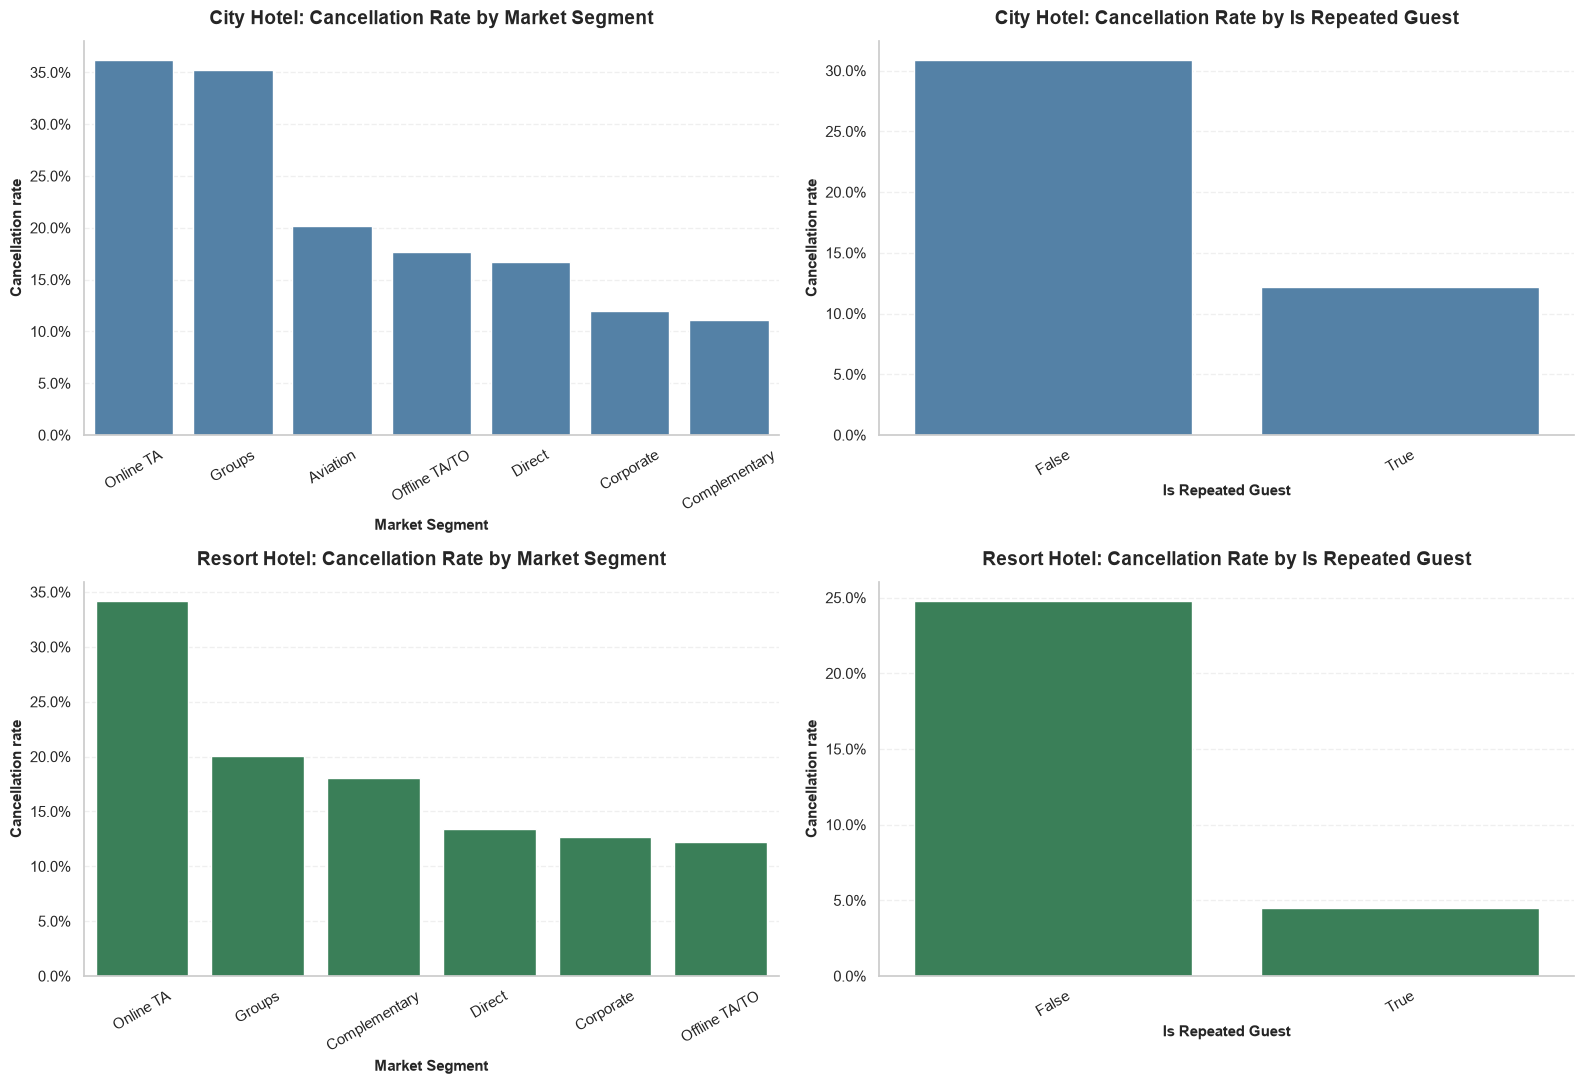

In [27]:
fig, axes = plt.subplots(2, 2, figsize=GRID_FIGSIZE)

for row, hotel in enumerate(HOTELS):
    subset = hotels[hotels["hotel"] == hotel]
    for col, column in enumerate(["market_segment", "is_repeated_guest"]):
        rates = cancellation_rate_by(subset, column).sort_values("cancellation_rate", ascending=False)
        ax = axes[row, col]
        sns.barplot(data=rates, x=column, y="cancellation_rate",
                    color=HOTEL_COLORS[hotel], ax=ax)
        label = column.replace("_", " ").title()
        style_axis(ax, f"{hotel}: Cancellation Rate by {label}", label, "Cancellation rate",
                   percent=True, rotate_x=30)

plt.tight_layout()
plt.show()

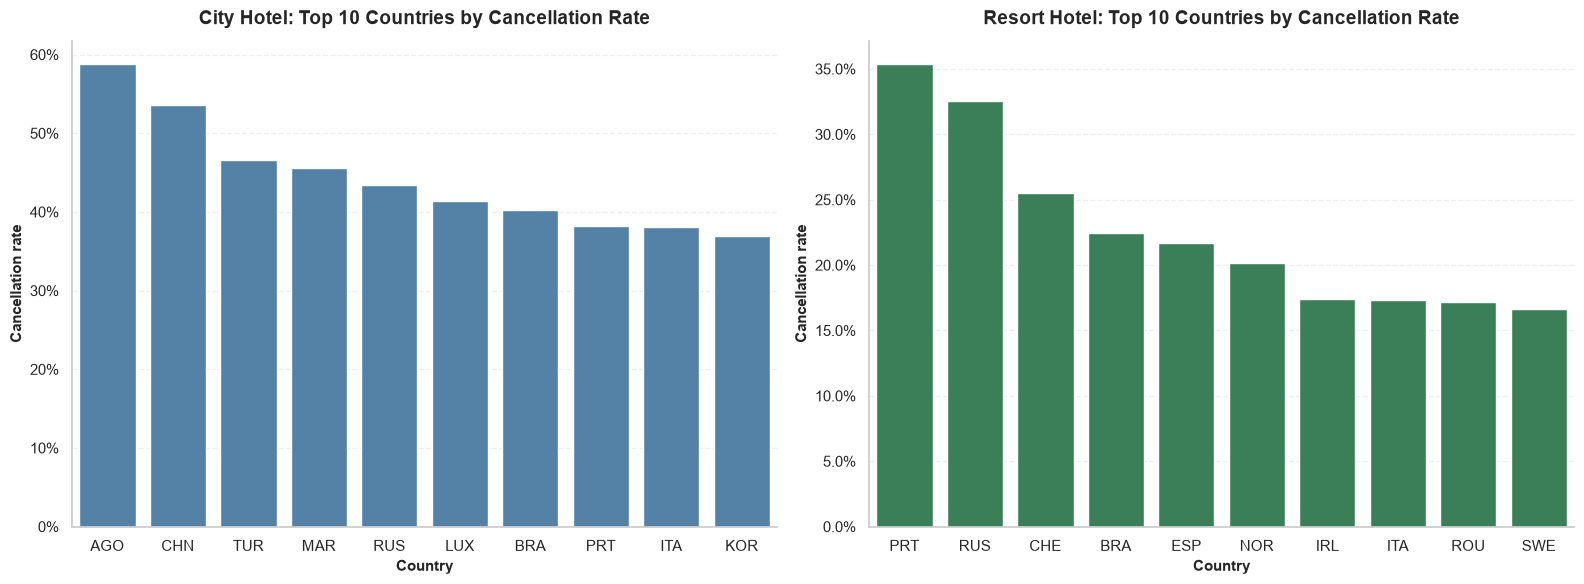

In [28]:
MIN_BOOKINGS_COUNTRY_CHART = 100   # ignore countries with very few bookings

def top_countries_by_cancellation(hotel, n=10):
    subset = hotels[hotels["hotel"] == hotel]
    countries = (subset.groupby("country")
                 .agg(bookings=("is_canceled", "size"), cancellation_rate=("is_canceled", "mean"))
                 .reset_index())
    countries = countries[countries["bookings"] > MIN_BOOKINGS_COUNTRY_CHART]
    return countries.sort_values("cancellation_rate", ascending=False).head(n)


fig, axes = plt.subplots(1, 2, figsize=WIDE_FIGSIZE)
for ax, hotel in zip(axes, HOTELS):
    sns.barplot(data=top_countries_by_cancellation(hotel), x="country", y="cancellation_rate",
                color=HOTEL_COLORS[hotel], ax=ax)
    style_axis(ax, f"{hotel}: Top 10 Countries by Cancellation Rate", "Country",
               "Cancellation rate", percent=True)

plt.tight_layout()
plt.show()

#### Step 2: Risk rules and tiers

Each booking is placed in the **highest** tier whose rule it matches.

| Tier | City Hotel | Resort Hotel |
|---|---|---|
| **Very high** | Non-refundable deposit | Non-refundable deposit |
| **Elevated** | Lead time of 9 months or more, **or** a country with a high cancellation rate | Arrival in June, July or August |
| **Baseline** | Everything else | Everything else |

The "high cancellation rate" countries are chosen by a data rule, not by hand: **at least 100 bookings and a cancellation rate of 50% or more.** The minimum size avoids picking countries whose rate is high only by chance.

In [29]:
RISK_TIERS = ["Very high", "Elevated", "Baseline"]
TIER_COLORS = {"Very high": "#C44E52", "Elevated": "#DD8452", "Baseline": "#8C8C8C"}

LONG_LEAD_DAYS = 270            # about 9 months
HIGH_RISK_MIN_BOOKINGS = 100
HIGH_RISK_MIN_RATE = 0.50

city_countries = (hotels[hotels["hotel"] == "City Hotel"].groupby("country")
                  .agg(bookings=("is_canceled", "size"), cancellation_rate=("is_canceled", "mean")))
city_high_risk_countries = city_countries[
    (city_countries["bookings"] >= HIGH_RISK_MIN_BOOKINGS)
    & (city_countries["cancellation_rate"] >= HIGH_RISK_MIN_RATE)
].index.tolist()
print("City Hotel high-risk countries:", city_high_risk_countries)


def assign_risk_tier(df, hotel):
    """Return the risk tier of every booking of one hotel."""
    is_non_refundable = df["deposit_type"] == "Non Refund"
    if hotel == "City Hotel":
        is_elevated = (df["lead_time"] >= LONG_LEAD_DAYS) | df["country"].isin(city_high_risk_countries)
    else:
        is_elevated = df["arrival_date_month"].isin(SUMMER_MONTHS)
    tier = np.select([is_non_refundable, is_elevated], ["Very high", "Elevated"], default="Baseline")
    return pd.Series(tier, index=df.index)


risk_tier = pd.concat([assign_risk_tier(group, hotel) for hotel, group in hotels.groupby("hotel")])
hotels = hotels.assign(risk_tier=pd.Categorical(risk_tier.reindex(hotels.index),
                                                categories=RISK_TIERS, ordered=True))

City Hotel high-risk countries: ['AGO', 'CHN']


#### Step 3: How good is each tier?

For every tier: its size, its cancellation rate with a 95% confidence interval (Wilson method), the share of **all** cancellations it captures, and a chi-square p-value for "is this tier different from the other bookings?".

A tier with a high rate but very few bookings has little effect on capacity, so the size columns matter as much as the rate.

In [30]:
def confidence_interval_for_mean(values, z=1.96):
    """95% confidence interval for a mean: mean ± z * s / sqrt(n)."""
    values = pd.Series(values).dropna()
    n = len(values)
    mean = values.mean()
    standard_error = values.std(ddof=1) / np.sqrt(n)   # s / sqrt(n)
    return mean - z * standard_error, mean + z * standard_error


def summarize_tiers(df):
    total_cancellations = df["is_canceled"].sum()
    rows = []
    for tier in RISK_TIERS:
        in_tier = df["risk_tier"] == tier
        tier_cancellations = df.loc[in_tier, "is_canceled"]      # the 0/1 values of this tier
        n = len(tier_cancellations)
        cancellations = int(tier_cancellations.sum())
        low, high = confidence_interval_for_mean(tier_cancellations)
        p_value = stats.chi2_contingency(pd.crosstab(in_tier, df["is_canceled"]))[1]
        rows.append({
            "tier": tier,
            "bookings": n,
            "share_of_bookings": round(n / len(df), 3),
            "cancellation_rate": round(cancellations / n, 3),
            "ci_low": round(low, 3),
            "ci_high": round(high, 3),
            "share_of_all_cancellations": round(cancellations / total_cancellations, 3),
            "p_value_vs_rest": f"{p_value:.2g}",
        })
    return pd.DataFrame(rows).set_index("tier")


tier_summaries = {hotel: summarize_tiers(hotels[hotels["hotel"] == hotel]) for hotel in HOTELS}

for hotel, summary in tier_summaries.items():
    print(f"=== {hotel} ===")
    print(summary.to_string())
    print()

=== City Hotel ===
           bookings  share_of_bookings  cancellation_rate  ci_low  ci_high  share_of_all_cancellations p_value_vs_rest
tier                                                                                                                  
Very high       844              0.016              0.972   0.960    0.983                       0.051               0
Elevated       2522              0.048              0.493   0.474    0.513                       0.078        9.2e-100
Baseline      49419              0.936              0.283   0.279    0.287                       0.871               0

=== Resort Hotel ===
           bookings  share_of_bookings  cancellation_rate  ci_low  ci_high  share_of_all_cancellations p_value_vs_rest
tier                                                                                                                  
Very high       193              0.006              0.839   0.787    0.891                       0.020         2.9e-85
Elevate

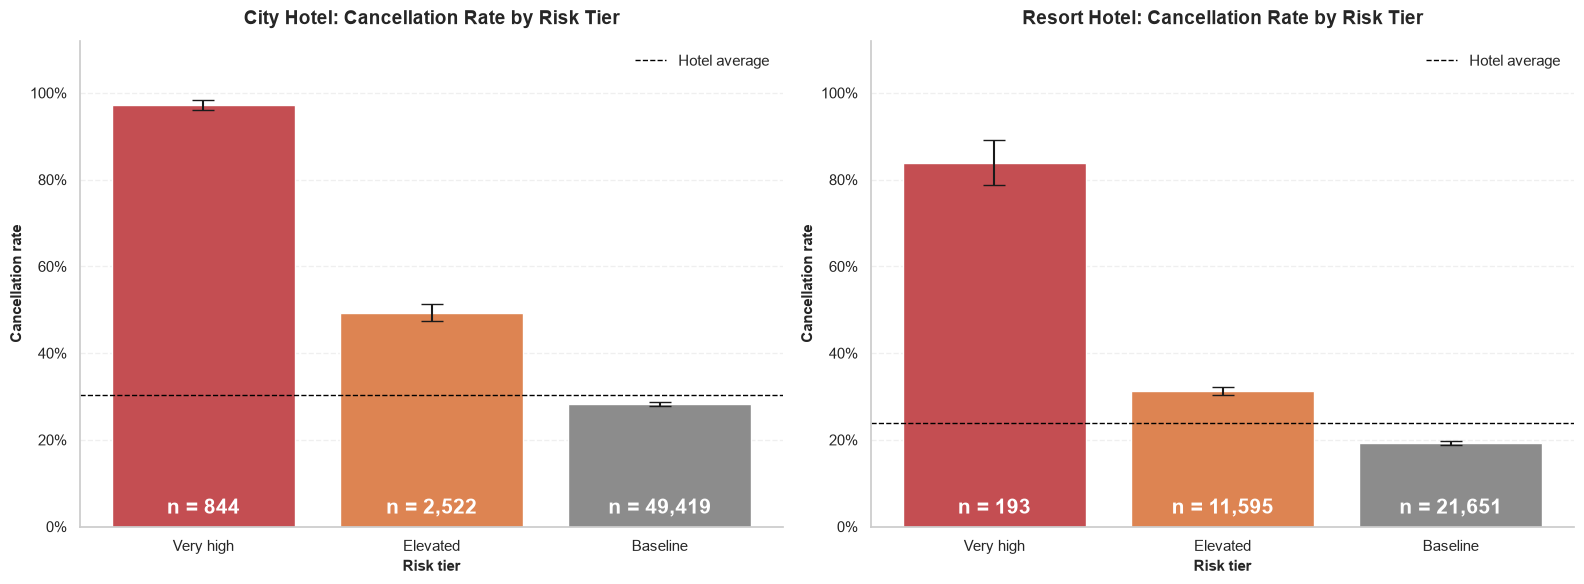

In [31]:
fig, axes = plt.subplots(1, 2, figsize=WIDE_FIGSIZE)

for ax, hotel in zip(axes, HOTELS):
    summary = tier_summaries[hotel]
    rates = summary["cancellation_rate"].to_numpy()
    errors = [rates - summary["ci_low"].to_numpy(), summary["ci_high"].to_numpy() - rates]

    ax.bar(summary.index.astype(str), rates, yerr=errors, capsize=8,
           color=[TIER_COLORS[tier] for tier in summary.index])
    ax.axhline(hotels.loc[hotels["hotel"] == hotel, "is_canceled"].mean(),
               color="black", linestyle="--", linewidth=1, label="Hotel average")

    for x_position, (tier, row) in enumerate(summary.iterrows()):
        ax.text(x_position, 0.03, f"n = {row['bookings']:,}", ha="center",
                color="white", fontsize=15, fontweight="bold")

    ax.set_ylim(0, 1.12)
    style_axis(ax, f"{hotel}: Cancellation Rate by Risk Tier", "Risk tier", "Cancellation rate", percent=True)
    ax.legend()

plt.tight_layout()
plt.show()

#### Step 4: When do cancellations happen?

For overbooking, what counts is how many cancellations arrive **close to the arrival date**, because only those leave an empty room that cannot be resold.
A cancellation is called **late** when it happens `LATE_CANCEL_DAYS` days or fewer before arrival. This threshold is an assumption and can be changed.

`reservation_status_date` is the date the booking was cancelled (for cancelled bookings), so the days before arrival are `arrival_date - reservation_status_date`.

In [32]:
LATE_CANCEL_DAYS = 7

days_before_arrival = (hotels["arrival_date"] - hotels["reservation_status_date"]).dt.days
hotels = hotels.assign(
    days_before_arrival=days_before_arrival,
    late_cancellation=(hotels["is_canceled"] == 1) & (days_before_arrival <= LATE_CANCEL_DAYS),
)

cancelled = hotels[hotels["is_canceled"] == 1]
timing = (cancelled.groupby(["hotel", "risk_tier"], observed=True)
          .agg(cancellations=("days_before_arrival", "size"),
               median_days_before_arrival=("days_before_arrival", "median"),
               share_late=("days_before_arrival", lambda days: (days <= LATE_CANCEL_DAYS).mean()))
          .round(3))
timing

cancellations  median_days_before_arrival  share_late
hotel        risk_tier                                                       
City Hotel   Very high            820                       100.0       0.051
             Elevated            1244                        38.0       0.166
             Baseline           13963                        30.0       0.232
Resort Hotel Very high            162                        60.0       0.136
             Elevated            3626                        56.0       0.101
             Baseline            4183                        30.0       0.204

#### Step 5: How many extra rooms can be sold?

For each hotel and each arrival date, count how many bookings were cancelled late. If the hotel sells `b` extra rooms for a night, it is **safe on that night** whenever at least `b` late cancellations happened.
The share of nights on which this holds is the **coverage** of that buffer. A higher target coverage means a smaller, safer buffer.

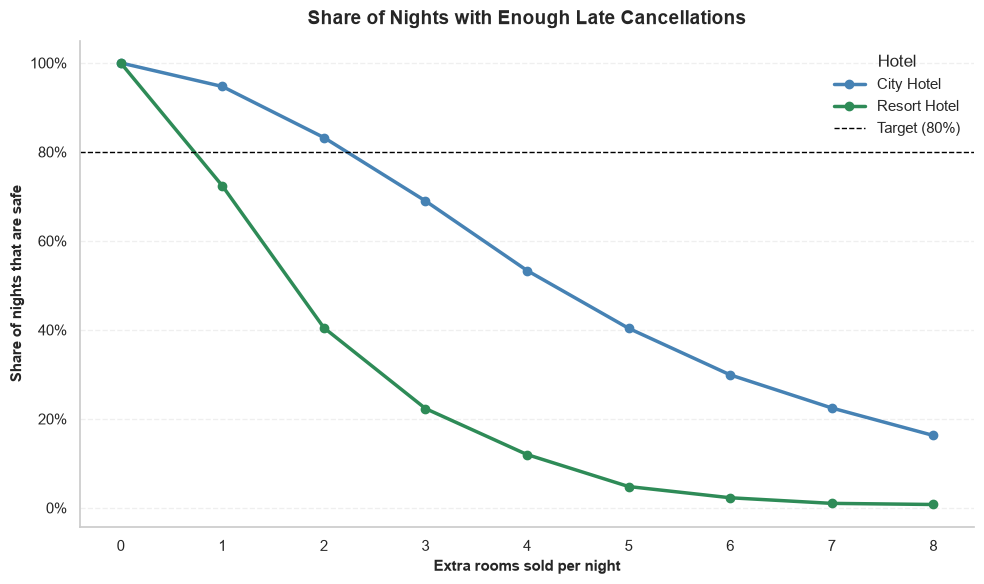

,City Hotel,Resort Hotel
extra_rooms_sold,,
0,1.00,1.00
1,0.95,0.72
2,0.83,0.40
3,0.69,0.22
4,0.53,0.12
5,0.40,0.05
6,0.30,0.02
7,0.22,0.01
8,0.16,0.01


In [33]:
daily = (hotels.groupby(["hotel", "arrival_date"])
         .agg(reservations=("hotel", "size"), late_cancellations=("late_cancellation", "sum"))
         .reset_index())

MAX_EXTRA_ROOMS = 8
TARGET_COVERAGE = 0.80

coverage = pd.DataFrame(
    {hotel: [(group["late_cancellations"] >= extra).mean() for extra in range(MAX_EXTRA_ROOMS + 1)]
     for hotel, group in daily.groupby("hotel")},
    index=pd.Index(range(MAX_EXTRA_ROOMS + 1), name="extra_rooms_sold"),
)

fig, ax = plt.subplots(figsize=(10, 6))
for hotel in HOTELS:
    ax.plot(coverage.index, coverage[hotel], marker="o", linewidth=2.5,
            color=HOTEL_COLORS[hotel], label=hotel)
ax.axhline(TARGET_COVERAGE, color="black", linestyle="--", linewidth=1, label=f"Target ({TARGET_COVERAGE:.0%})")
ax.legend()
style_axis(ax, "Share of Nights with Enough Late Cancellations", "Extra rooms sold per night",
           "Share of nights that are safe", percent=True, legend_title="Hotel")
plt.tight_layout()
plt.show()

coverage.round(2)

#### Recommendation

The next cell prints the recommendation using the numbers computed above.

In [ ]:
for hotel in HOTELS:
    hotel_coverage = coverage[hotel]
    hotel_daily = daily[daily["hotel"] == hotel]
    avg_reservations = hotel_daily["reservations"].mean()
    avg_late = hotel_daily["late_cancellations"].mean()
    very_high = timing.loc[(hotel, "Very high")]

    # largest number of extra rooms that is "safe" on at least TARGET_COVERAGE of nights
    extra_rooms = int(hotel_coverage[hotel_coverage >= TARGET_COVERAGE].index.max())

    print(f"=== {hotel} ===")
    print(f"On an average night the hotel has {avg_reservations:.1f} reservations, "
          f"and {avg_late:.1f} of them are cancelled late "
          f"({LATE_CANCEL_DAYS} days or fewer before arrival).")
    print()

    if extra_rooms > 0:
        print(f"RECOMMENDATION: sell up to {extra_rooms} extra room(s) per night "
              f"(about {extra_rooms / avg_reservations:.1%} of the average reservations).")
        print(f"WHY: on {hotel_coverage[extra_rooms]:.0%} of past nights, at least {extra_rooms} bookings "
              f"were cancelled late, so the extra room(s) would have been covered. "
              f"The target was {TARGET_COVERAGE:.0%} of nights.")
    else:
        print("RECOMMENDATION: do not overbook on a regular basis.")
        print(f"WHY: selling even 1 extra room would have been covered on only {hotel_coverage[1]:.0%} of past nights "
              f"(on the other {1 - hotel_coverage[1]:.0%} no booking was cancelled late). "
              f"The target was {TARGET_COVERAGE:.0%} of nights.")
    print()

    print(f"NON-REFUNDABLE BOOKINGS: they are the most likely to be cancelled, but they are cancelled early "
          f"(median {very_high['median_days_before_arrival']:.0f} days before arrival; "
          f"only {very_high['share_late']:.0%} of their cancellations happen in the last {LATE_CANCEL_DAYS} days). "
          f"Their rooms can be sold again, so they should not be used to justify overbooking.")
    print()

print("Assumption: these numbers assume the hotel is full on the night. "
      "If rooms are empty anyway, overbooking is not needed.")

=== City Hotel ===
On an average night the hotel has 66.6 reservations, and 4.4 of them are cancelled late (7 days or fewer before arrival).

RECOMMENDATION: sell up to 2 extra room(s) per night (about 3.0% of the average reservations).
WHY: on 83% of past nights, at least 2 bookings were cancelled late, so the extra room(s) would have been covered. The target was 80% of nights.

NON-REFUNDABLE BOOKINGS: they are the most likely to be cancelled, but they are cancelled early (median 100 days before arrival; only 5% of their cancellations happen in the last 7 days). Their rooms can be sold again, so they should not be used to justify overbooking.

=== Resort Hotel ===
On an average night the hotel has 42.2 reservations, and 1.6 of them are cancelled late (7 days or fewer before arrival).

RECOMMENDATION: do not overbook on a regular basis.
WHY: selling even 1 extra room would have been covered on only 72% of past nights (on the other 28% no booking was cancelled late). The target was 80%

**Reading the result**

- The risk tiers show **who** is likely to cancel (non-refundable deposits, very long lead times, a few countries, summer in the Resort Hotel).
- The timing check shows that the riskiest bookings cancel **early**, so they are useful for planning and for reselling rooms, but not for covering last-minute no-shows.
- The overbooking buffer therefore comes from the **daily count of late cancellations**, not from the cancellation rate of any tier.

**Limitations**

- **Data:** two hotels in one country, 2015 to 2017. Behaviour may have changed.
- **No capacity or cost data:** the buffer is measured in extra rooms per night. The real cost of walking a guest (finding another hotel, compensation, reputation) is unknown, so the target coverage is a business decision. Change `TARGET_COVERAGE` to see other risk levels.
- **Late cancellation is defined as 7 days or fewer before arrival.** Another threshold gives other numbers.
- **Duplicates were removed.** Without a booking ID, some may be real group bookings. Keeping them raises the cancellation rates, so rates depend on this decision.
- **In-sample:** tiers and buffers are evaluated on the same data used to create them. A future test on new data is needed to confirm them.

## 6. Hypothesis testing

The charts show differences. A hypothesis test asks whether a difference is **real or could be chance**.

- **H0 (null hypothesis):** there is no difference; what we see is chance.
- **H1 (alternative hypothesis):** there is a real difference.
- **p-value:** if H0 were true, the probability of seeing a difference at least this large by chance. A p-value below `ALPHA = 0.05` means chance is an unlikely explanation.

A small p-value says the difference is *unlikely to be chance*, not that it is large or important. That is why the actual rates are always shown next to the p-value, and why "not significant" means "not enough evidence", not "no difference".

| Question | Data | Test |
|---|---|---|
| 1, 2, 3 | Cancelled or not, for 2 or more groups | Chi-square test on a table of counts |
| 4 | Revenue (numeric, skewed), 2 groups | Mann-Whitney U (and Welch t-test for comparison) |

The chi-square test is always run on **real counts**, never on percentages.

In [35]:
def chi_square_by_group(group, outcome, group_labels=None):
    """Chi-square test of independence on a table of counts; also returns the group rates."""
    table = pd.crosstab(group, outcome)
    if group_labels is not None:
        table.index = group_labels
    _, p_value, _, expected = stats.chi2_contingency(table)
    rates = table[1] / table.sum(axis=1)
    return table, rates, p_value, expected


resort = hotels[hotels["hotel"] == "Resort Hotel"]

### Test 1: Are refundable-deposit bookings cancelled less often? (Resort Hotel)

- **H0:** the cancellation rate of refundable-deposit bookings equals the rate of all other bookings in the Resort Hotel.
- **H1:** the two rates differ.

In [36]:
table, rates, p_value, expected = chi_square_by_group(
    resort["deposit_type"] == "Refundable", resort["is_canceled"],
    group_labels=["Other deposit types", "Refundable"],
)
print(table, "\n")
print(rates.round(3), "\n")
report_test(p_value)

is_canceled              0     1
Other deposit types  25392  7955
Refundable              76    16 

Other deposit types    0.239
Refundable             0.174
dtype: float64 

p-value = 0.183  ->  fail to reject H0 (not enough evidence of a difference) at alpha = 0.05


### Test 2: Is the cancellation rate higher in June to August? (Resort Hotel)

- **H0:** the cancellation rate in June to August equals the rate in the other months.
- **H1:** the two rates differ.

The test uses real counts. No adjustment for July and August having more years of data is needed, because a *rate* is a ratio and is not inflated by extra years.

In [37]:
table, rates, p_value, expected = chi_square_by_group(
    resort["arrival_date_month"].isin(SUMMER_MONTHS), resort["is_canceled"],
    group_labels=["Other months", "Jun-Aug"],
)
print(table, "\n")
print(rates.round(3), "\n")
report_test(p_value)

is_canceled       0     1
Other months  17496  4326
Jun-Aug        7972  3645 

Other months    0.198
Jun-Aug         0.314
dtype: float64 

p-value = 4.5e-123  ->  reject H0 (the difference is statistically significant) at alpha = 0.05


### Test 3: Do the three deposit types have different cancellation rates? (Resort Hotel)

- **H0:** the cancellation rate is the same for all three deposit types.
- **H1:** at least one deposit type has a different rate.

The test only says that *some* difference exists. Which groups differ is read from the rates.

In [38]:
table, rates, p_value, expected = chi_square_by_group(resort["deposit_type"], resort["is_canceled"])
print(table, "\n")
print(rates.round(3), "\n")
report_test(p_value)

is_canceled       0     1
deposit_type             
No Deposit    25361  7793
Non Refund       31   162
Refundable       76    16 

deposit_type
No Deposit    0.235
Non Refund    0.839
Refundable    0.174
dtype: float64 

p-value = 5.31e-85  ->  reject H0 (the difference is statistically significant) at alpha = 0.05


### Test 4: Do the two top countries bring different revenue? (City Hotel)

- **H0:** bookings from the two countries have the same revenue distribution.
- **H1:** the distributions differ.

Only **non-cancelled** bookings of the City Hotel are used, and the two countries are the top 2 from Question 6. Revenue is strongly skewed, so the **Mann-Whitney U** test (which compares ranks) is the main test. The Welch t-test is shown for comparison.

In [39]:
city_stays = hotels[(hotels["hotel"] == "City Hotel") & (hotels["is_canceled"] == 0)]
country_a, country_b = top_countries("City Hotel", "bookings").head(2)["country"]

revenue_a = city_stays.loc[city_stays["country"] == country_a, "total_revenue"]
revenue_b = city_stays.loc[city_stays["country"] == country_b, "total_revenue"]

print(f"{country_a}: {len(revenue_a):,} bookings, median revenue {revenue_a.median():.1f}, skewness {revenue_a.skew():.2f}")
print(f"{country_b}: {len(revenue_b):,} bookings, median revenue {revenue_b.median():.1f}, skewness {revenue_b.skew():.2f}")
print()

print("Mann-Whitney U (main test):")
_, p_mann_whitney = stats.mannwhitneyu(revenue_a, revenue_b)
report_test(p_mann_whitney)

print("\nWelch t-test (comparison):")
_, p_t_test = stats.ttest_ind(revenue_a, revenue_b, equal_var=False)
report_test(p_t_test)

PRT: 7,889 bookings, median revenue 168.0, skewness 2.97
FRA: 5,828 bookings, median revenue 324.0, skewness 2.17

Mann-Whitney U (main test):
p-value < 1e-300  ->  reject H0 (the difference is statistically significant) at alpha = 0.05

Welch t-test (comparison):
p-value < 1e-300  ->  reject H0 (the difference is statistically significant) at alpha = 0.05


## 7. Summary

**What was done:** the raw bookings were cleaned and checked for outliers, eight business questions were answered with charts, and four of the observed differences were tested statistically.